# BlocoRocha A.02: Momentum Growth, equal weights, monthly rebalancing

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/tiago-baptistalopes/bloco-rocha/blob/main/notebooks/A02_equal_weight_monthly.ipynb)

| Item | Rule |
|---|---|
| Universe | Every dollar-listed United States and euro-listed European firm with a market value of at least €1.5 billion at fund creation, 2005-01-25 (set `N_PER_REGION` to sample instead) |
| Entry | Top quartile 12-1 month momentum **and** top half price-to-book; filled to 50 names by combined rank |
| Exit | Debt-to-equity up 100% or more year on year, or price-to-book up by 10% or less year on year; firms showing either signal cannot enter |
| Rebalancing | Monthly (on the 25th, or the next trading day): entry, exit checks and reset to equal weights across the 50 holdings (`REBALANCE_MONTHS = 12` for annual) |
| Listings | United States stocks listed in dollars and European stocks listed in euros only |
| Currency | Euro; United States dollar positions fully hedged (local returns, carry ignored) |
| Risk-free rate | 12-month EURIBOR (European Central Bank monthly average), used in Sharpe, Sortino and Omega ratios and shown as a cash line |
| Benchmarks | S&P 500 total return (dollar, treated as hedged like the fund's dollar positions); equal-weighted universe |
| Persona tests | Maximum drawdown no worse than −35%; value-at-risk-equivalent volatility 12–20% (Summary Risk Indicator class 4) |

Prices: yfinance. Fundamentals: Compustat via Wharton Research Data Services (cached to `data/fundamentals.csv`).

In [2]:
%pip install -q yfinance quantstats wrds

Note: you may need to restart the kernel to use updated packages.


In [3]:
import os
import time
import logging
import numpy as np
import pandas as pd
import yfinance as yf
import quantstats as qs
import matplotlib.pyplot as plt

START = pd.Timestamp('2005-01-25')
HISTORY_START = '2003-12-01'
N_HOLD = 50
N_PER_REGION = None
MIN_MCAP_EUR = 1.5e9
MOM_Q, PB_Q = 0.75, 0.50
DE_JUMP, PB_DROP = 1.0, 0.10
MDD_LIMIT, VEV_RANGE, RHP_YEARS = -0.35, (0.12, 0.20), 20
SEED = 42
CURRENCIES = ('USD', 'EUR')
WEIGHTING = 'equal'
REBALANCE_MONTHS = 1
EURO_SUFFIXES = {'AS', 'BR', 'PA', 'DE', 'F', 'HM', 'MU', 'BE', 'DU', 'SG', 'MI', 'MC', 'LS', 'IR', 'VI', 'HE', 'AT', 'LU'}
SUFFIX_CCY = {'L': 'GBp', 'SW': 'CHF', 'ST': 'SEK', 'CO': 'DKK', 'OL': 'NOK', 'WA': 'PLN'}

def currency(t):
    if '.' not in t:
        return 'USD'
    suffix = t.rsplit('.', 1)[1]
    return 'EUR' if suffix in EURO_SUFFIXES else SUFFIX_CCY.get(suffix, suffix)
WRDS_USERNAME = ''
DATA = 'data'
os.makedirs(DATA, exist_ok=True)

## 1. Universe: every firm above the size threshold at fund creation

All United States and European firms in Compustat with fiscal year 2004 data, pre-screened at a market value of €1 billion, then screened exactly at €1.5 billion on 2005-01-25 with yfinance prices. Compustat includes firms delisted since 2005; the share that yfinance cannot price measures the survivorship bias.

In [4]:
def cached(name, fetch, dates=True):
    path = f'{DATA}/{name}.csv'
    if os.path.exists(path):
        return pd.read_csv(path, index_col=0, parse_dates=dates)
    df = fetch()
    if df.empty or df.isna().all().any():
        print(f'{name}: download empty or incomplete, not cached; rerun later')
    else:
        df.to_csv(path)
    return df

CCYS = ['USD', 'GBP', 'CHF', 'SEK', 'DKK', 'NOK', 'PLN']

def fetch_fx():
    fx = yf.download([f'EUR{c}=X' for c in CCYS], start=HISTORY_START, auto_adjust=True, progress=False)['Close']
    fx.columns = [c[3:6] for c in fx.columns]
    return fx

fx = cached('fx', fetch_fx).ffill().bfill()
fx['EUR'] = 1.0

In [5]:
EUROPE = ['GBR','FRA','DEU','NLD','BEL','LUX','IRL','ESP','PRT','ITA','CHE','AUT','SWE','DNK','NOR','FIN','GRC']
FUNDA_US = "f.indfmt='INDL' and f.datafmt='STD' and f.popsrc='D' and f.consol='C'"
FUNDA_EU = "f.indfmt='INDL' and f.datafmt='HIST_STD' and f.popsrc='I' and f.consol='C'"

def wrds_query(sql):
    import wrds
    db = wrds.Connection(wrds_username=WRDS_USERNAME or None)
    if not os.path.exists(os.path.expanduser('~/.pgpass')):
        db.create_pgpass_file()
    df = db.raw_sql(sql)
    db.close()
    return df

def fetch_compustat_universe():
    return wrds_query(f'''
        select f.gvkey, f.tic as symbol, 'US' as region, f.curcd, f.prcc_f * f.csho * 1e6 as mcap_local
        from comp.funda f join comp.company c on c.gvkey = f.gvkey
        where {FUNDA_US} and f.fyear = 2004 and c.loc = 'USA' and f.prcc_f * f.csho >= 1000
        union all
        select f.gvkey, s.isin as symbol, 'EU' as region, d.curcdd as curcd, d.prccd * d.cshoc as mcap_local
        from comp.g_funda f
        join comp.g_company c on c.gvkey = f.gvkey
        join comp.g_security s on s.gvkey = f.gvkey and s.iid = c.prirow
        join lateral (select prccd, cshoc, curcdd from comp.g_secd x
                      where x.gvkey = s.gvkey and x.iid = s.iid and x.datadate <= f.datadate and x.datadate > f.datadate - 10
                      order by x.datadate desc limit 1) d on true
        where {FUNDA_EU} and f.fyear = 2004 and c.loc in ({','.join(f"'{x}'" for x in EUROPE)})''').set_index('gvkey')

cu = cached('compustat_universe', fetch_compustat_universe, dates=False)
cu.index = cu.index.astype(str).str.zfill(6)
cu = cu[~cu.index.duplicated(keep='last')]
rate = fx.loc[:'2004-12-31'].iloc[-1]
cu['mcap_eur'] = cu['mcap_local'] / cu['curcd'].map(rate)
cu = cu[cu['mcap_eur'] >= 1e9]
cu['region'].value_counts()

region
US    1288
EU     548
Name: count, dtype: int64

In [6]:
def yahoo_symbol(isin):
    try:
        quotes = yf.Search(isin, max_results=5).quotes
        return quotes[0]['symbol'] if quotes else 'NOT_FOUND'
    except Exception:
        return None

path = f'{DATA}/yahoo_map.csv'
ymap = pd.read_csv(path, index_col=0, dtype=str)['ticker'] if os.path.exists(path) else pd.Series(dtype=str, name='ticker')
ymap.index = ymap.index.astype(str).str.zfill(6)
todo = [g for g in cu.index if g not in ymap.index or pd.isna(ymap.get(g))]
for g in todo:
    s_, r = cu.loc[g, 'symbol'], cu.loc[g, 'region']
    ymap[g] = s_.replace('.', '-') if r == 'US' else yahoo_symbol(s_)
    if r == 'EU':
        time.sleep(0.5)
if todo:
    ymap.rename('ticker').to_csv(path)
print(f'{ymap.isna().sum()} lookups failed (rerun this cell to retry), {(ymap == "NOT_FOUND").sum()} not on Yahoo Finance')
ymap = ymap[ymap.notna() & (ymap != 'NOT_FOUND')]
ymap = ymap[ymap.index.isin(cu.index) & ~ymap.duplicated()]
found = cu.loc[ymap.index, 'region'].value_counts()
listing_ok = [(currency(t) == 'USD') if cu.loc[g, 'region'] == 'US' else (currency(t) == 'EUR') for g, t in ymap.items()]
ymap = ymap[[ok and currency(t) in CURRENCIES for ok, t in zip(listing_ok, ymap)]]
TICKERS = sorted(ymap)
REGION = pd.Series(cu.loc[ymap.index, 'region'].values, index=ymap.values)
GVKEY = pd.Series(ymap.index, index=ymap.values)

0 lookups failed (rerun this cell to retry), 201 not on Yahoo Finance


## 2. Prices and currencies (yfinance)

In [7]:
class LogCapture(logging.Handler):
    def __init__(self):
        super().__init__()
        self.lines = []
    def emit(self, record):
        self.lines.append(record.getMessage())

yf_log = LogCapture()
logging.getLogger('yfinance').addHandler(yf_log)

def download(tickers, batch=100, pause=60, retries=3):
    out, limited = [], []
    for i in range(0, len(tickers), batch):
        chunk = tickers[i:i + batch]
        for attempt in range(retries):
            yf_log.lines.clear()
            close = yf.download(chunk, start=HISTORY_START, auto_adjust=True, progress=False, threads=True)['Close']
            close = (close.to_frame(chunk[0]) if isinstance(close, pd.Series) else close).reindex(columns=chunk)
            hit = [t for t in chunk if any('Rate' in l and f"'{t}'" in l for l in yf_log.lines)]
            if not hit:
                break
            time.sleep(pause)
        limited += hit
        out.append(close.drop(columns=hit))
        time.sleep(2)
    if limited:
        print(f'{len(limited)} tickers still rate-limited; rerun this cell later to fetch only those')
    return pd.concat(out, axis=1)

path = f'{DATA}/prices.csv'
px = pd.read_csv(path, index_col=0, parse_dates=True) if os.path.exists(path) else pd.DataFrame()
missing = [t for t in TICKERS if t not in px.columns]
if missing:
    px = pd.concat([px, download(missing)], axis=1)
    px.to_csv(path)
empty = [t for t in TICKERS if t not in px.columns or px[t].isna().all()]
print(f'{len(TICKERS)} tickers, {len(TICKERS) - len(empty)} with prices, {len(empty)} without (delisted or rate-limited)')

1493 tickers, 870 with prices, 623 without (delisted or rate-limited)


In [8]:
px = px[[t for t in TICKERS if t in px.columns and px[t].notna().any()]].dropna(how='all')
CCY = pd.Series({t: currency(t) for t in px.columns})
fx = fx.reindex(px.index).ffill().bfill()

def to_eur(t):
    c = CCY[t]
    return px[t] * (0.01 if c == 'GBp' else 1.0) / fx['GBP' if c == 'GBp' else c]

px_eur = pd.DataFrame({t: to_eur(t) for t in px.columns})
px_ret = pd.DataFrame({t: px[t] if CCY[t] == 'USD' else px_eur[t] for t in px.columns})
CCY.value_counts()

USD    665
EUR    205
Name: count, dtype: int64

## 3. Fundamentals (Compustat via Wharton Research Data Services)

Debt = long-term debt + debt in current liabilities. Fiscal year $y-1$ is used at the January rebalance of year $y$ (accepted look-ahead bias). Compustat amounts are in millions.

In [9]:
def fetch_fundamentals():
    keys = ','.join(f"'{g}'" for g in cu.index)
    return wrds_query(f'''
        select f.gvkey, f.fyear, f.curcd, f.ceq * 1e6 as ceq, (coalesce(f.dltt,0) + coalesce(f.dlc,0)) * 1e6 as debt,
               f.csho * 1e6 as shares
        from comp.funda f where {FUNDA_US} and f.fyear between 2002 and 2026 and f.gvkey in ({keys})
        union all
        select f.gvkey, f.fyear, f.curcd, f.ceq * 1e6, (coalesce(f.dltt,0) + coalesce(f.dlc,0)) * 1e6, d.cshoc
        from comp.g_funda f
        join comp.g_company c on c.gvkey = f.gvkey
        left join lateral (select cshoc from comp.g_secd x
                           where x.gvkey = f.gvkey and x.iid = c.prirow and x.datadate <= f.datadate and x.datadate > f.datadate - 10
                           order by x.datadate desc limit 1) d on true
        where {FUNDA_EU} and f.fyear between 2002 and 2026 and f.gvkey in ({keys})''').set_index('gvkey')

fund = cached('fundamentals', fetch_fundamentals, dates=False).reset_index()
fund['gvkey'] = fund['gvkey'].astype(str).str.zfill(6)
tick = pd.Series(GVKEY.index, index=GVKEY.values)
fund['ticker'] = fund['gvkey'].map(tick)
fund = fund.dropna(subset=['ticker', 'ceq']).drop_duplicates(['ticker', 'fyear'], keep='last')
ceq, debt, shares = (fund.pivot(index='fyear', columns='ticker', values=v) for v in ('ceq', 'debt', 'shares'))
curcd = fund.groupby('ticker')['curcd'].last()
de = (debt / ceq).where(ceq > 0)

## 4. Exact size screen at fund creation and annual signals

In [10]:
pxf = px_eur.ffill(limit=10)
pxr = px_ret.ffill(limit=10)
DATES = sorted({px.index[px.index >= m][0] for m in pd.date_range(START, px.index[-1], freq=pd.DateOffset(months=REBALANCE_MONTHS))})

def at(df, d):
    rows = df.loc[:d]
    return rows.iloc[-1] if len(rows) else pd.Series(np.nan, index=df.columns)

def book_eur(d):
    y = d.year - 1
    return ceq.reindex([y]).iloc[0] / curcd.reindex(ceq.columns).map(at(fx, d)).astype(float)

def mcap_eur(d):
    return at(pxf, d).reindex(shares.columns) * shares.reindex([d.year - 1]).iloc[0]

def pb(d):
    b = book_eur(d)
    return (mcap_eur(d) / b).where(b > 0)

def momentum(d):
    return at(pxr, d - pd.DateOffset(months=1)) / at(pxr, d - pd.DateOffset(months=12)) - 1

mcap0 = mcap_eur(DATES[0]).dropna()
UNIVERSE = sorted(mcap0[mcap0 >= MIN_MCAP_EUR].index)
if N_PER_REGION:
    rng = np.random.default_rng(SEED)
    UNIVERSE = [t for r in ('US', 'EU') for t in rng.choice(sorted(t for t in UNIVERSE if REGION[t] == r),
                size=min(N_PER_REGION, sum(REGION[t] == r for t in UNIVERSE)), replace=False)]

funnel = pd.DataFrame({
    'Compustat, pre-screen above €1bn': cu['region'].value_counts(),
    'Found on Yahoo Finance': found,
    'Dollar-listed (United States) or euro-listed (Europe)': REGION.value_counts(),
    'Priced on 2005-01-25': REGION[at(pxf, DATES[0]).dropna().index.intersection(REGION.index)].value_counts(),
    'Universe (above €1.5bn)': REGION[UNIVERSE].value_counts()}).T
funnel['Total'] = funnel.sum(axis=1)
funnel

,US,EU,Total
"Compustat, pre-screen above €1bn",1288,548,1836
Found on Yahoo Finance,1288,346,1634
Dollar-listed (United States) or euro-listed (Europe),1288,205,1493
Priced on 2005-01-25,617,195,812
Universe (above €1.5bn),302,98,400


## 5. Portfolio rules

At each rebalance date $t$ (monthly): holdings that trigger an exit signal are sold,
$$\frac{D/E_{y-1}}{D/E_{y-2}} - 1 \ge 1.0 \quad \text{or} \quad \frac{P/B_t}{P/B_{t-12\text{ months}}} - 1 \ge 0.10, $$
the remaining holdings are kept, and free slots are filled first with names in the top momentum quartile and the top price-to-book half, then with the best remaining combined rank $\tfrac{1}{2}\left(\text{rank}_{\text{momentum}} + \text{rank}_{P/B}\right)$. Holdings are then reset to equal weights, $w_i = 1/N$; weights drift with prices until the next monthly rebalance.

In [11]:
holdings, log = {}, []
held = []
for d in DATES:
    alive = at(pxf, d).reindex(UNIVERSE).dropna().index
    mom, pbs = momentum(d).reindex(alive), pb(d).reindex(alive)
    y = d.year - 1
    de_jump = (de.loc[y] / de.loc[y - 1] - 1 >= DE_JUMP).reindex(alive, fill_value=False) if {y, y - 1} <= set(de.index) else pd.Series(False, index=alive)
    pb_drop = (pbs / pb(d - pd.DateOffset(years=1)).reindex(alive) - 1 <= PB_DROP)
    signal = de_jump | pb_drop
    exits = [t for t in held if t not in alive or signal.get(t, False)]
    held = [t for t in held if t not in exits]
    ok = mom.dropna().index.intersection(pbs.dropna().index).difference(signal[signal].index)
    score = (mom[ok].rank(pct=True) + pbs[ok].rank(pct=True)) / 2
    passed = (mom[ok] >= mom[ok].quantile(MOM_Q)) & (pbs[ok] >= pbs[ok].quantile(PB_Q))
    order = pd.DataFrame({'passed': passed, 'score': score}).sort_values(['passed', 'score'], ascending=False).index
    entries = [t for t in order if t not in held][:max(N_HOLD - len(held), 0)]
    held = held + entries
    if WEIGHTING == 'market_cap':
        mc = mcap_eur(d).reindex(held)
        w = mc.fillna(mc.median()) / mc.fillna(mc.median()).sum()
    else:
        w = pd.Series(1 / len(held), index=held)
    holdings[d] = w
    log.append({'date': d, 'holdings': len(held), 'entries': len(entries), 'exits': len(exits),
                'exit_leverage': sum(bool(de_jump.get(t, False)) for t in exits),
                'exit_price_to_book': sum(bool(pb_drop.get(t, False)) for t in exits),
                'passed_both_filters': int(passed.sum()),
                'largest_weight': w.max(), 'effective_holdings': 1 / (w ** 2).sum()})
log = pd.DataFrame(log).set_index('date')
log.groupby(log.index.year).agg({'entries': 'sum', 'exits': 'sum', 'exit_leverage': 'sum', 'exit_price_to_book': 'sum',
                                  'passed_both_filters': 'mean', 'largest_weight': 'max', 'effective_holdings': 'min'}).round(2)

,entries,exits,exit_leverage,exit_price_to_book,passed_both_filters,largest_weight,effective_holdings
date,,,,,,,
2005,91,41,0,41,21.25,0.02,50.0
2006,83,83,5,78,24.00,0.02,50.0
2007,83,83,4,80,19.58,0.02,50.0
2008,104,133,7,129,5.42,0.08,12.0
2009,68,39,3,37,13.83,0.07,15.0
2010,52,52,1,51,29.17,0.02,50.0
2011,83,83,1,82,18.67,0.02,50.0
2012,53,53,5,48,20.75,0.02,50.0
2013,34,34,3,31,30.08,0.02,50.0


## 6. Backtest

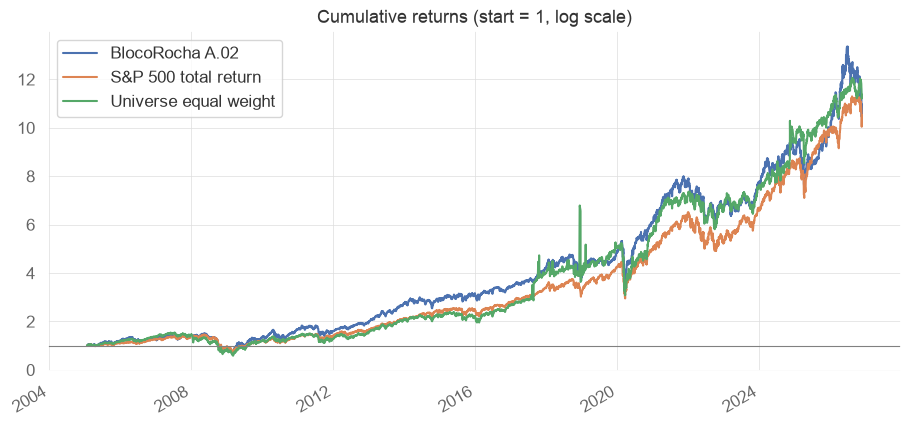

BlocoRocha A.02          10.961852
S&P 500 total return     10.520545
Universe equal weight    11.368696
Name: 2026-11-23 00:00:00, dtype: float64

In [ ]:
def backtest(weights, prices):
    dates = list(weights) + [prices.index[-1]]
    parts = []
    for d0, d1 in zip(dates[:-1], dates[1:]):
        w = weights[d0]
        p = prices.loc[d0:d1, w.index].ffill()
        parts.append((p / p.iloc[0]).mul(w, axis=1).sum(axis=1).pct_change().dropna())
    return pd.concat(parts)

fund_r = backtest(holdings, px_ret).rename('BlocoRocha A.02')
bench_holdings = {}
for d in DATES:
    alive = at(pxf, d).reindex(UNIVERSE).dropna().index
    bench_holdings[d] = pd.Series(1 / len(alive), index=alive)
bench_r = backtest(bench_holdings, px_ret).rename('Universe equal weight')

def fetch_sp500():
    return yf.download('^SP500TR', start=HISTORY_START, auto_adjust=True, progress=False)['Close']

sp500 = cached('sp500', fetch_sp500).iloc[:, 0]
sp500_r = sp500.reindex(px.index.union(sp500.index)).ffill().pct_change().reindex(fund_r.index).rename('S&P 500 total return')

cum = (1 + pd.concat([fund_r, sp500_r, bench_r], axis=1)).cumprod()
cum = pd.concat([pd.DataFrame(1.0, index=[DATES[0]], columns=cum.columns), cum])
ax = cum.plot(figsize=(11, 5), logy=True, title='Cumulative returns (start = 1, log scale)')
ax.axhline(1, color='grey', lw=0.8)
plt.show()
cum.iloc[-1]

## Risk-free rate: 12-month EURIBOR

European Central Bank Data Portal series `FM.M.U2.EUR.RT.MM.EURIBOR1YD_.HSTA` (monthly average, percent per annum), applied to every trading day of its month. quantstats converts it to a daily rate, $r_{f,d} = (1 + r_{f})^{1/252} - 1$, for the excess-return ratios; cumulative returns stay gross.

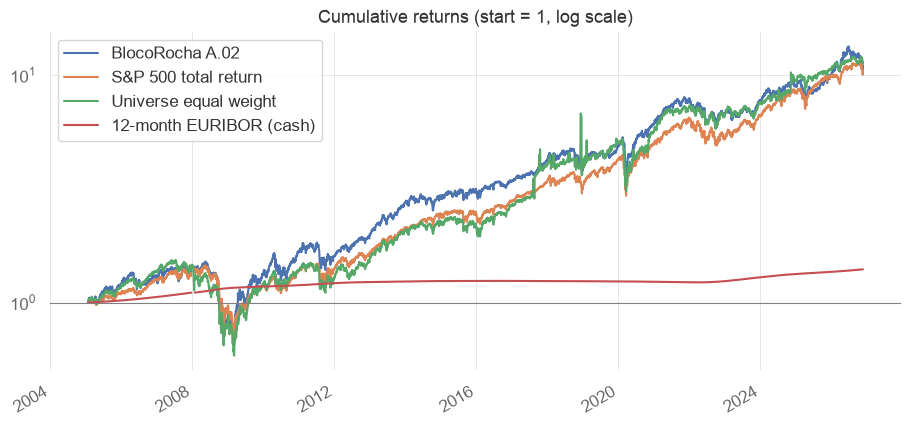

,Average 12-month EURIBOR,Minimum,Maximum
0,0.0154,-0.005,0.0539


In [13]:
ECB_URL = 'https://data-api.ecb.europa.eu/service/data/FM/M.U2.EUR.RT.MM.EURIBOR1YD_.HSTA?format=csvdata&startPeriod=2003-12'

def fetch_euribor():
    raw = pd.read_csv(ECB_URL)
    return raw.set_index(pd.to_datetime(raw['TIME_PERIOD']))[['OBS_VALUE']].rename(columns={'OBS_VALUE': 'euribor_12m'})

euribor = cached('euribor_12m', fetch_euribor)['euribor_12m'] / 100
rf = euribor.reindex(euribor.index.union(fund_r.index)).ffill().reindex(fund_r.index)
cash_r = ((1 + rf) ** (1 / 252) - 1).rename('12-month EURIBOR (cash)')

cum = (1 + pd.concat([fund_r, sp500_r, bench_r, cash_r], axis=1)).cumprod()
cum = pd.concat([pd.DataFrame(1.0, index=[DATES[0]], columns=cum.columns), cum])
ax = cum.plot(figsize=(11, 5), logy=True, title='Cumulative returns (start = 1, log scale)')
ax.axhline(1, color='grey', lw=0.8)
plt.show()
pd.DataFrame({'Average 12-month EURIBOR': [rf.mean()], 'Minimum': [rf.min()], 'Maximum': [rf.max()]}).round(4)

In [14]:
strategies = pd.concat([fund_r, bench_r], axis=1)
m = qs.reports.metrics(strategies, benchmark=sp500_r, rf=rf, mode='full', display=False)
m.loc['Treynor Ratio'] = qs.reports.metrics(strategies, benchmark=sp500_r, rf=float(rf.mean()), mode='full', display=False).loc['Treynor Ratio']
m

,Benchmark,BlocoRocha A.02,Universe equal weight
Start Period,2005-01-26,2005-01-26,2005-01-26
End Period,2026-11-23,2026-11-23,2026-11-23
Risk-Free Rate,1.54,1.54,1.54
Time in Market,0.98,1.0,1.0
Cumulative Return,9.52,9.96,11.88
...,...,...,...
Win Year,0.86,0.82,0.82
Beta,-,0.92,0.93
Alpha,-,0.01,0.04
Correlation,-,0.88%,0.59%


## 7. Persona tests

Value-at-risk-equivalent volatility (Commission Delegated Regulation (EU) 2017/653, Annex II), with $\sigma$, $\mu_1$ (skewness) and $\mu_2$ (excess kurtosis) of daily log returns, $N = 256\,T$ trading days over the recommended holding period $T$:
$$\text{VaR}_{\text{return}} = \sigma\sqrt{N}\left(-1.96 + 0.474\frac{\mu_1}{\sqrt{N}} - 0.0687\frac{\mu_2}{N} + 0.146\frac{\mu_1^2}{N}\right) - 0.5\,\sigma^2 N, \qquad \text{VEV} = \frac{\sqrt{3.842 - 2\,\text{VaR}_{\text{return}}} - 1.96}{\sqrt{T}}$$

In [15]:
def vev(r, T=RHP_YEARS):
    x = np.log1p(r.dropna())
    s, m1, m2, N = x.std(), x.skew(), x.kurt(), 256 * T
    var = s * np.sqrt(N) * (-1.96 + 0.474 * m1 / np.sqrt(N) - 0.0687 * m2 / N + 0.146 * m1**2 / N) - 0.5 * s**2 * N
    return (np.sqrt(3.842 - 2 * var) - 1.96) / np.sqrt(T)

def persona_tests(r):
    mdd, v = qs.stats.max_drawdown(r), vev(r)
    return pd.DataFrame({
        'value': [mdd, v, qs.stats.volatility(r), qs.stats.value_at_risk(r)],
        'target': [f'>= {MDD_LIMIT:.0%}', f'{VEV_RANGE[0]:.0%} to {VEV_RANGE[1]:.0%}', 'reference', 'reference (daily, 95%)'],
        'pass': [mdd >= MDD_LIMIT, VEV_RANGE[0] <= v <= VEV_RANGE[1], None, None]},
        index=['Maximum drawdown', 'Value-at-risk-equivalent volatility', 'Annualised volatility', 'Historical value at risk'])

tests = persona_tests(fund_r)
print('Persona conditions met:', bool(tests['pass'].dropna().all()))
pd.concat({'BlocoRocha A.02': tests, 'S&P 500 total return': persona_tests(sp500_r), 'Universe Equal Weights': persona_tests(bench_r)}, axis=1)

Persona conditions met: False


BlocoRocha A.02                          \
                                              value                  target   
Maximum drawdown                          -0.559999                 >= -35%   
Value-at-risk-equivalent volatility        0.198611              12% to 20%   
Annualised volatility                      0.196193               reference   
Historical value at risk                  -0.019826  reference (daily, 95%)   

                                           S&P 500 total return  \
                                      pass                value   
Maximum drawdown                     False            -0.515199   
Value-at-risk-equivalent volatility   True             0.189574   
Annualised volatility                 None             0.187523   
Historical value at risk              None            -0.018942   

                                                                    \
                                                     target   pass   
Maximum drawdown                                    >= -35%  False   
Value-at-risk-equivalent volatility              12% to 20%   True   
Annualised volatility                             reference   None   
Historical value at risk             reference (daily, 95%)   None   

                                    Universe Equal Weights  \
                                                     value   
Maximum drawdown                                 -0.620096   
Value-at-risk-equivalent volatility               0.294794   
Annualised volatility                             0.298349   
Historical value at risk                         -0.030314   

                                                                    
                                                     target   pass  
Maximum drawdown                                    >= -35%  False  
Value-at-risk-equivalent volatility              12% to 20%  False  
Annualised volatility                             reference   None  
Historical value at risk             reference (daily, 95%)   None